# **Обязательное домашнее задание 1.**

**Выбор датасета** "Дефекты Стальных пластин" /kaggle/input/datasets/eouedraogo4/steel-plates-faults
**Причина:** по первому образованию я инженер-металловед, надеюсь или применить свои профессиональные данные, чтобы анализ был более качественным или чтобы мне было не так "страшно" при получении новых навыков и они накладывались уже на знакомый профиль металловедения. 

**Гипотезы:** 

* **Н1.** Если убрать все признаки с высокой корреляцией, то качество моделей вырастет, признаковое пространство сократится, а обучение будет быстрее и проще.
* **Н2.** Из-за сильного дисбаланса классов accurancy будет менее информативна, нежели F1.
* **Н3.** Линейные модели покажут лучшее качество, нежели леса из-за линейной природы данных.
* **Н4.** Геометрические размеры будут как признаки важнее, нежели признаки освещенности и характеристики индексов.
* **Н5.** Вид и классификация дефектов царапин геометрически не сильно различается в зависимости от марки стали (марки сталей очень схожи - горячекатаная, отличаются только прочностными свойствами и областью применения, характер и вид дефектов должен быть очень схожим).

**Выводы:**

1. Гипотеза Н1 подтвердилась частично. Простое удаление коррелирующих признаков через SelectKBest ухудшило качество моделей, однако умный отбор RFE с 21 признаком повысил F1-macro для Gradient Boosting до 0.8235, а метод PCA хорошо подошел для сжатия данных перед линейной моделью, но навредил деревьям.
2. Гипотеза Н2 подтвердилась. Dummy-модель показала Accuracy 0.35 при F1-macro всего 0.07, а обученная модель имела Accuracy около 0.70 при F1-macro 0.75, при этом матрица ошибок выявила, что модель путает размытые дефекты Bumps и Pastry, сваливая их в Other_Faults, что доказывает необходимость использования F1-macro вместо Accuracy.
3. Гипотеза Н3 не подтвердилась. Ансамбли деревьев оказались значительно лучше, Random Forest показал F1-macro 0.8035, Gradient Boosting 0.8147, а Логистическая регрессия остановилась на 0.6509, что доказывает нелинейную природу данных.
4. Гипотеза Н4 подтвердилась частично. В топ-5 важных признаков вошли как геометрические LogOfAreas и Pixels_Areas, так и контекстный Length_of_Conveyer, а также оптические Minimum_of_Luminosity, что говорит о комплексном влиянии формы, положения и яркости дефекта.
5. Гипотеза Н5 подтвердилась. Статистический T-тест и визуальный анализ показали, что геометрия и размеры дефектов для марок A300 и A400 практически не отличаются, а признак марки стали получил крайне низкую важность при обучении модели.
6. Данные представлены 1941 объектом с 34 числовыми колонками, пропусков нет, задача является многоклассовой классификацией с сильным дисбалансом классов, а признаки делятся на геометрические, оптические, пространственные признаки.
7. Корреляционный анализ выявил сильную мультиколлинеарность между координатами.
8. Кросс-валидация показала, что Gradient Boosting имеет лучшее среднее качество F1-macro 0.7880 при минимальном разбросе 0.0191, Random Forest показал стабильный результат 0.7743 с разбросом 0.0319, а Логистическая регрессия оказалась слабее 0.6688 с самым высоким разбросом 0.0428.
9. RandomizedSearch оказался в несколько раз быстрее GridSearch при сопоставимом качестве, что позволило незначительно улучшить итоговые метрики моделей.
10. ROC-AUC лучшей модели составил 0.6454, что близко к случайному угадыванию и говорит о плохом разделении классов на уровне вероятностей.
11. Нормализованная матрица ошибок показала, что к Other_Faults все неявные случаи, при этом модель отлично распознает четкие царапины K_Scatch и Z_Scratch.
12. SelectKBest с f_classif оценивает признаки изолированно и не подходит для этих данных, RFE с 21 признаком сохраняет нелинейные связи и повышает качество деревьев, а PCA хорошо работает с линейными моделями, но ломает логику деревьев.
13. Ансамбли деревьев, особенно Gradient Boosting, являются лучшим выбором для классификации дефектов стальных пластин, данные нелинейны и имеют сильный дисбаланс, поэтому для честной оценки необходимо использовать F1-macro и матрицу ошибок, а для повышения качества - умный отбор признаков RFE и подбор гиперпараметров.

# Шаг 0. Установка окужения, подгрузка датасета и проверка, что все корректно отработало.

In [1]:
#основные бибилиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#подгрузка датасета из kaggle и проверка первых 5 строчек
df = pd.read_csv("/kaggle/input/datasets/eouedraogo4/steel-plates-faults/SteelPlatesFaults.csv")
df.head()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


**Вывод по шагу 0:** библиотеки все загружены для работы, данные подгрузились.

# Шаг 1. EDA данных, приблизимся к пониманию природы данных и сути задачи.

In [3]:
df.columns

Index(['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas',
       'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity',
       'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer',
       'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness',
       'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index',
       'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas',
       'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index',
       'SigmoidOfAreas', 'Pastry', 'Z_Scratch', 'K_Scatch', 'Stains',
       'Dirtiness', 'Bumps', 'Other_Faults'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empt

In [5]:
df.describe()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
count,1941.000000,1941.000000,1.941000e+03,1.941000e+03,1941.000000,1941.000000,1941.000000,1.941000e+03,1941.000000,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,571.136012,617.964451,1.650685e+06,1.650739e+06,1893.878413,111.855229,82.965997,2.063121e+05,84.548686,130.193715,...,0.083288,-0.131305,0.585420,0.081401,0.097888,0.201443,0.037094,0.028336,0.207110,0.346728
std,520.690671,497.627410,1.774578e+06,1.774590e+06,5168.459560,301.209187,426.482879,5.122936e+05,32.134276,18.690992,...,0.500868,0.148767,0.339452,0.273521,0.297239,0.401181,0.189042,0.165973,0.405339,0.476051
min,0.000000,4.000000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,37.000000,...,-0.991000,-0.998900,0.119000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,51.000000,192.000000,4.712530e+05,4.712810e+05,84.000000,15.000000,13.000000,9.522000e+03,63.000000,124.000000,...,-0.333300,-0.195000,0.248200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,435.000000,467.000000,1.204128e+06,1.204136e+06,174.000000,26.000000,25.000000,1.920200e+04,90.000000,127.000000,...,0.095200,-0.133000,0.506300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1053.000000,1072.000000,2.183073e+06,2.183084e+06,822.000000,84.000000,83.000000,8.301100e+04,106.000000,140.000000,...,0.511600,-0.066600,0.999800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1705.000000,1713.000000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,253.000000,...,0.991700,0.642100,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Первичный выводы, которые можно сделать на данный момент:

Это задача многоклассовой классификации, так как есть 7 типов дефектов (последние 7 столбцов) - рябь (pastry), изогнутая царапина (z_scratch), линейная царапина (k_scratch), пятна (stains), грязь типа включений-окалины (dirtiness), ямки (bumps), другие дефекты (other_faults)
Все признаки условно можно поделить по категориям: геометрические - по ограничевающему прямоугольнику (x_min, x_max, y_min, y_max); количеству пикселей, занимаемые дефектом (pixels_areas, x_perimeter, y_perimeter), тип освещения (min/max_of_luminosity, sum_of_luminosity), тип стали (a300, a400, thinkness), вещественные числа по дефектам (все остальное)

Предложение: нужно внимательно изучить, как категории признаков вляют на качество разделения на классы.
Все данные у нас заполнены, данные численные.

In [6]:
target_col = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains',
       'Dirtiness', 'Bumps', 'Other_Faults']
feature_col = ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas',
       'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity',
       'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer',
       'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness',
       'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index',
       'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas',
       'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index',
       'SigmoidOfAreas']

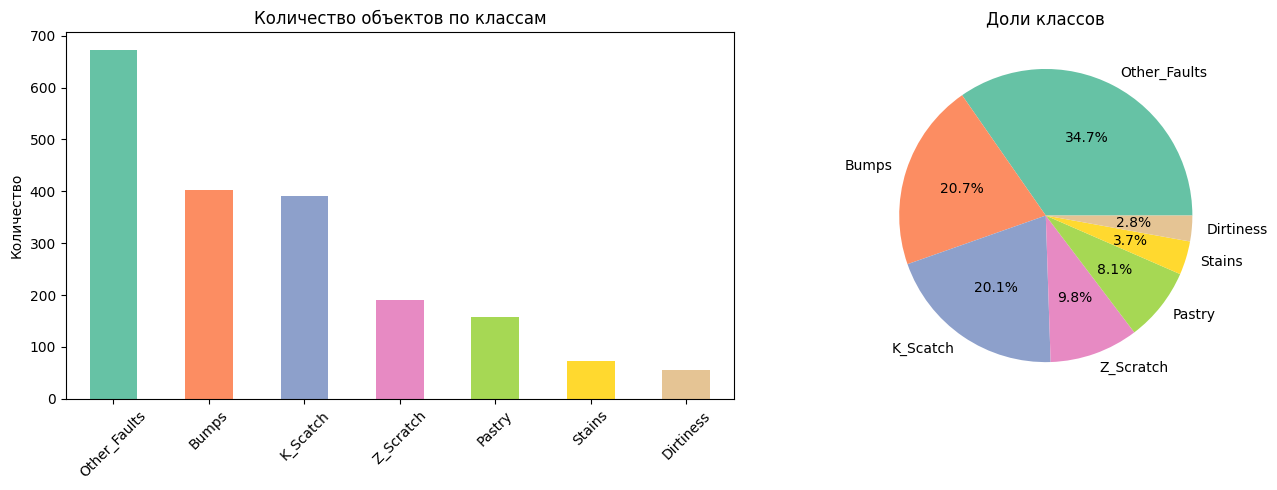

In [7]:
#график, отображающий распределение sample по классам
y_text = df[target_col].idxmax(axis=1)
class_counts = y_text.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_counts.plot.bar(ax=axes[0], color=sns.color_palette("Set2"))
axes[0].set_title("Количество объектов по классам")
axes[0].set_ylabel("Количество")
axes[0].tick_params(axis="x", rotation=45) 

class_counts.plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette("Set2"))
axes[1].set_ylabel("")
axes[1].set_title("Доли классов")

plt.tight_layout()
plt.show()

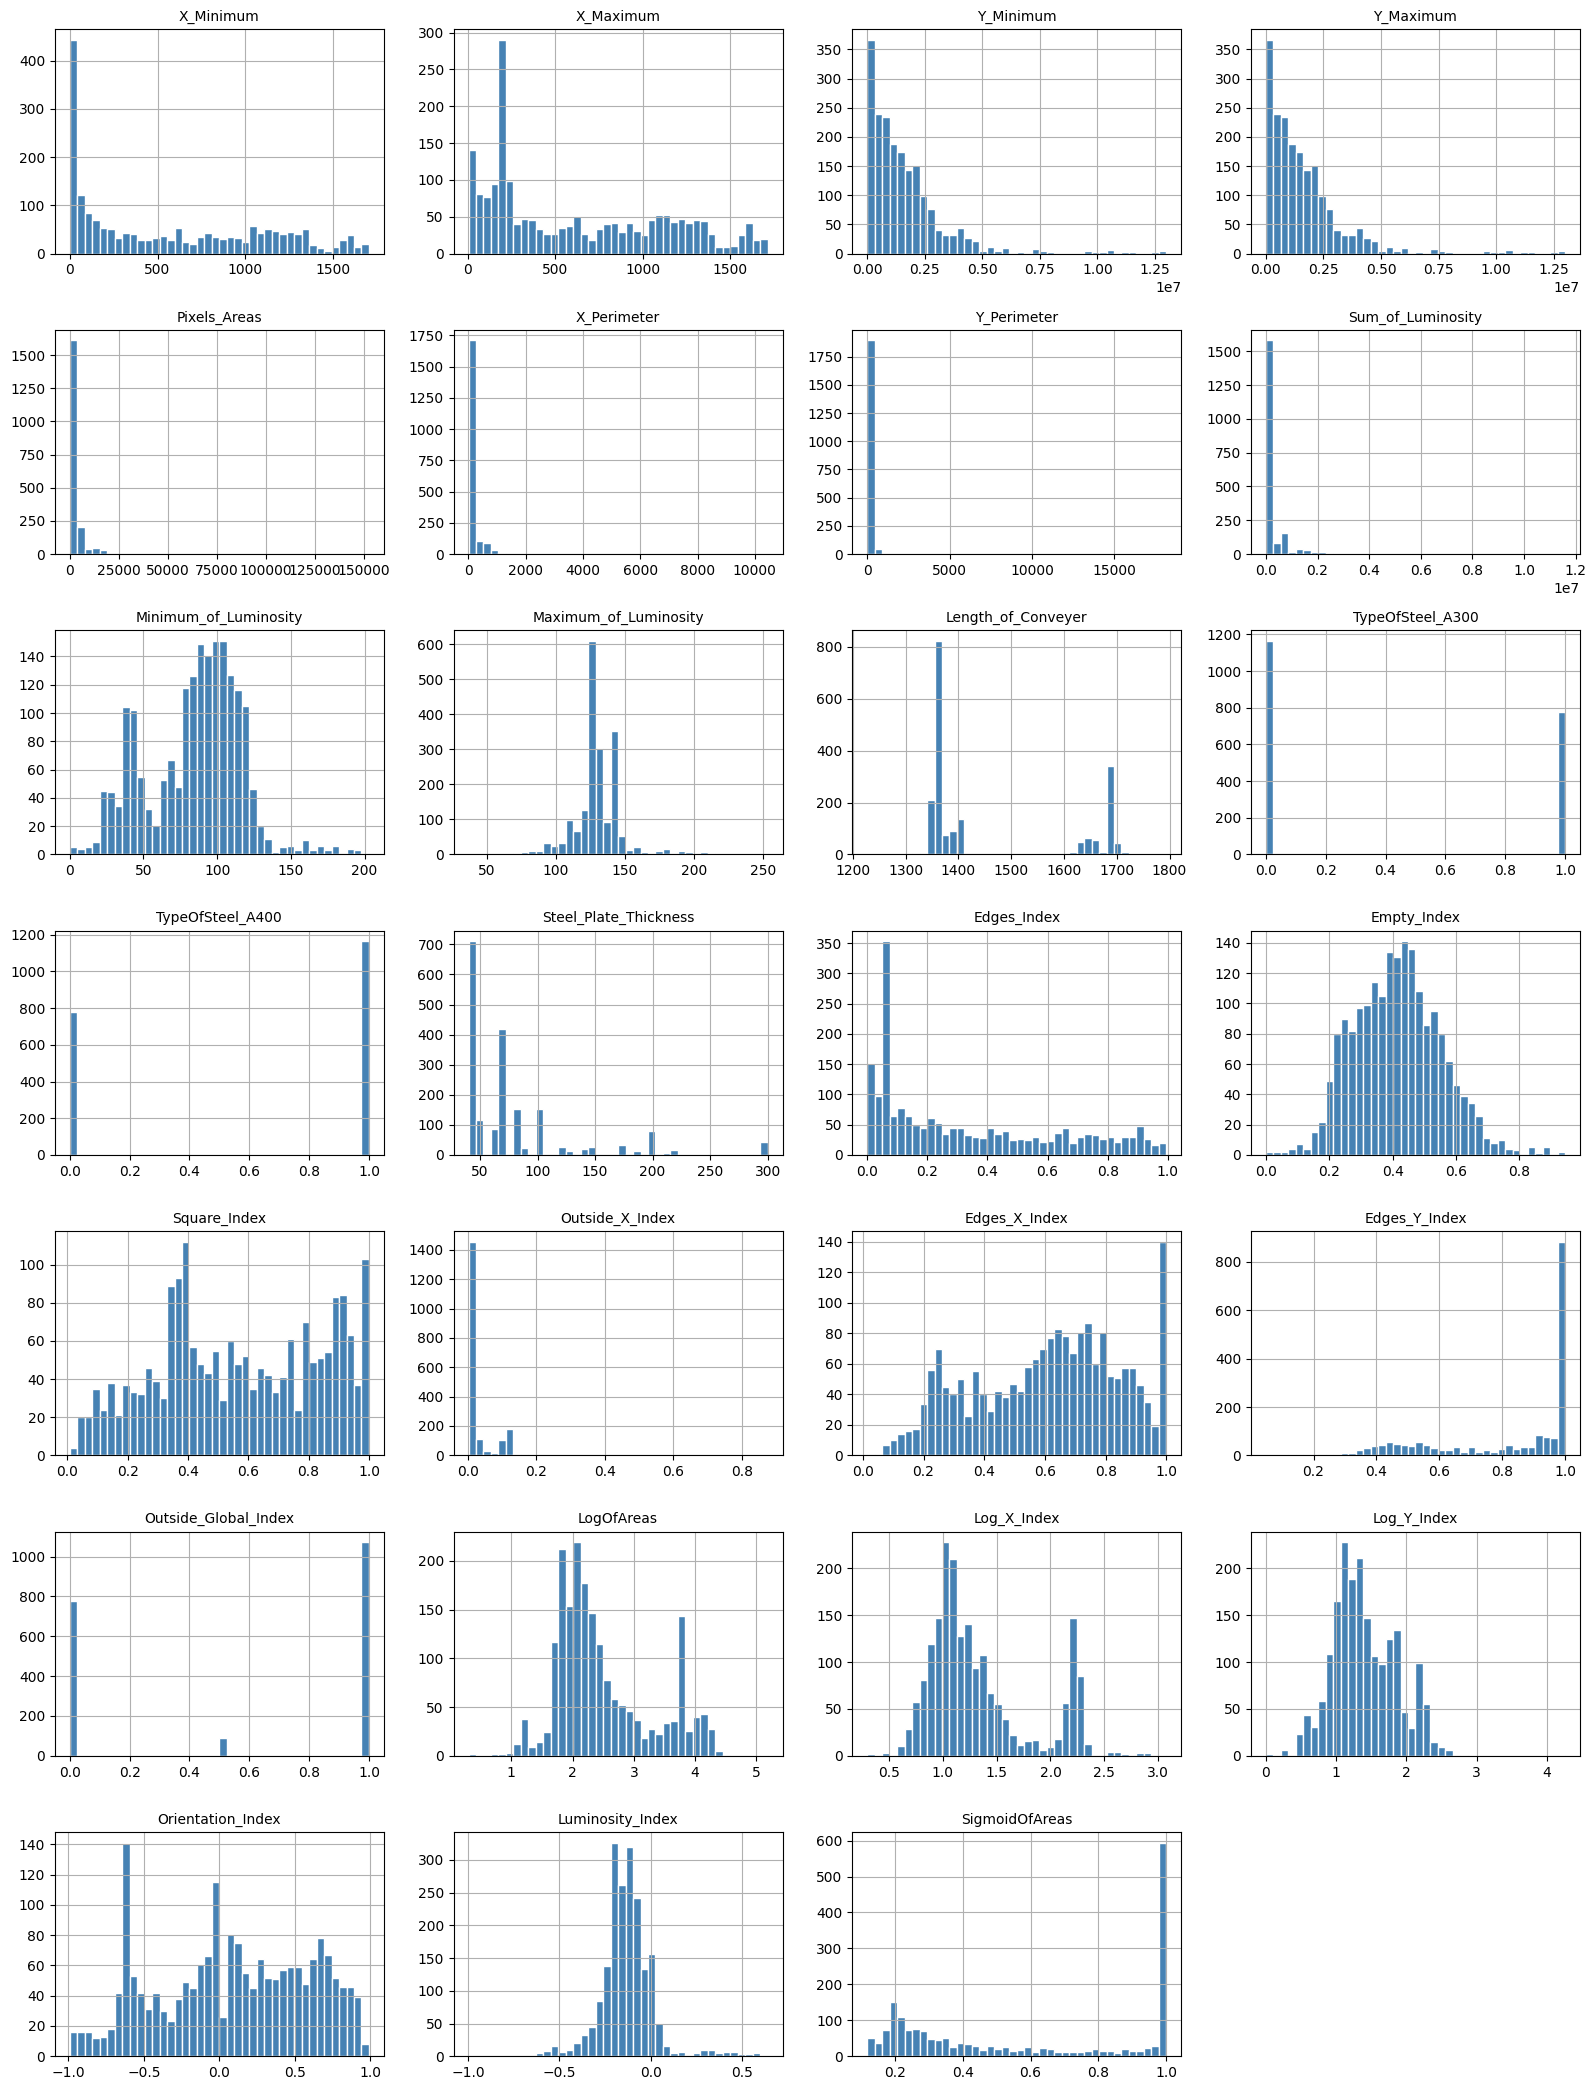

In [8]:
#рассмотрим рапределение признаков
n_cols = len(feature_col)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(feature_col):
    df[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(feature_col), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

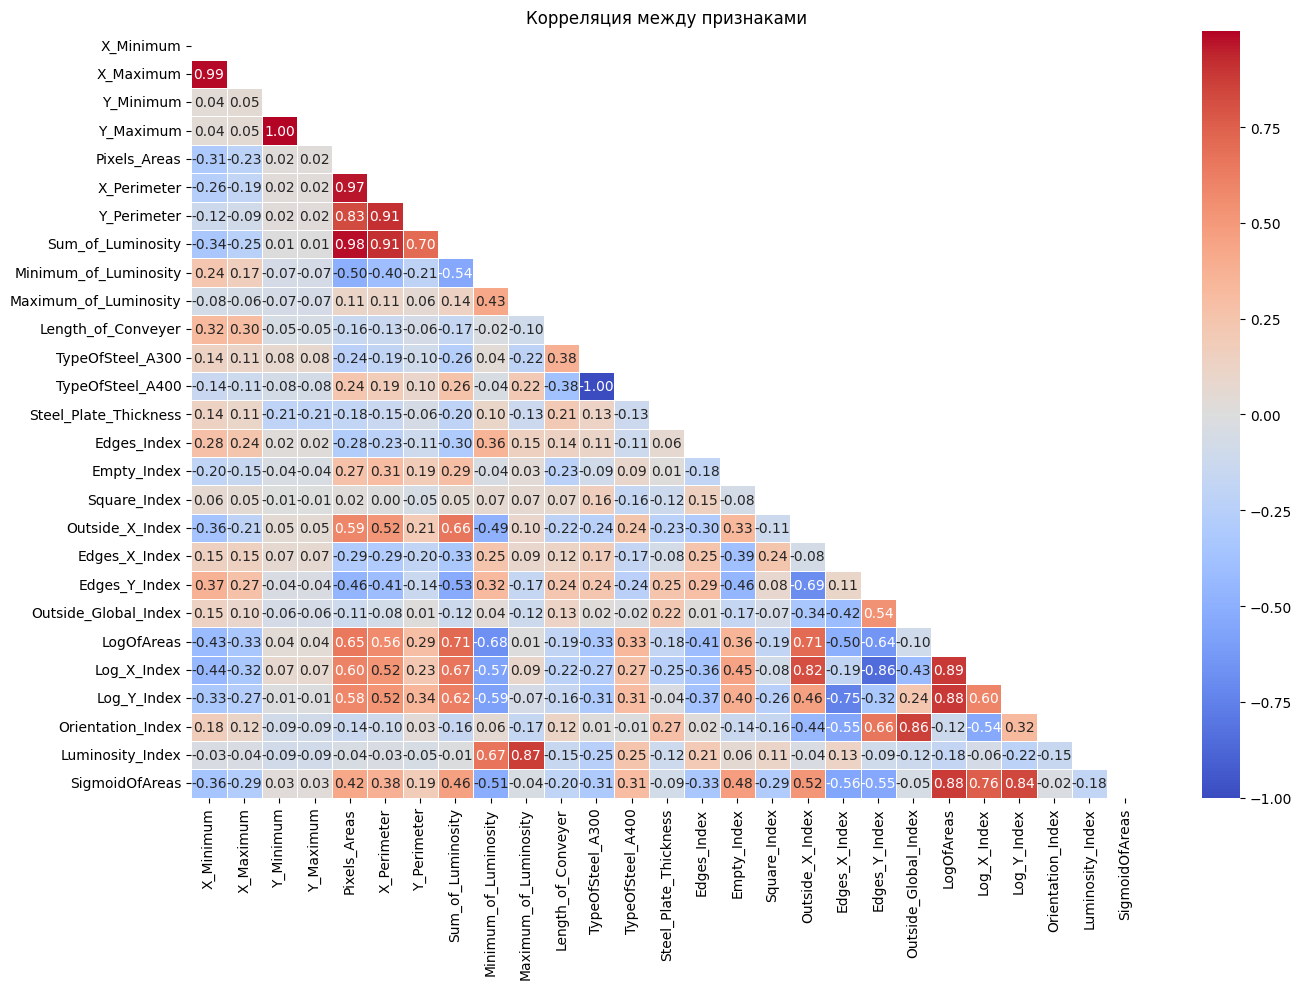

In [9]:
plt.figure(figsize=(14, 10))
corr = df[feature_col].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

**Выводы:** распределение по классам у нас неравномерное, больше всего данных соответсвтует классу другие дефекты. Большое количество признаков, причем многие из них соответствует геометрии изначально ограничевающего прямоугольника, далее геометрии дефекта, а затем уже условиям съемки. Есть ощущение, что нужно уменьшить признаковое пространство путем замены признаков, чтобы они были более показательными так как по графикам признаком видно, что есть большое количество несбалансированных данных, преобладание нулевых значений.

Если рассмотреть корреляционную матрицу, то можно увидеть, что большое количество признаков которые прямо-/обратно- коррелируют между собой.

**ИТОГОВЫЕ ГИПОТЕЗЫ**

* Н1. Если убрать все признаки с высокой корреляцией, то качество моделей вырастет, признаковое пространство сократится, а обучение будет быстрее и проще.
* Н2. Из-за сильного дисбаланса классов accurancy будет менее информативна, нежели F1.
* Н3. Линейные модели покажут лучшее качество, нежели леса из-за линейной природы данных.
* Н4. Геометрические размеры будут как признаки важнее, нежели признаки освещенности и характеристики индексов.
* Н5. Вид и классификация дефектов царапин геометрически не сильно различается в зависимости от марки стали (марки сталей очень схожи - горячекатаная, отличаются только прочностными свойствами и областью применения, характер и вид дефектов должен быть очень схожим).


# Шаг 2. Проверка гипотез. Работа с данными. Построение моделей классификации.

Реализуем сначала без преобразований алгоритм классификакции из sklearn: логистическая регрессия, случайный лес и градиентный бустинг.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

X = df.drop(target_col, axis = 1)
y_text = df[target_col].idxmax(axis = 1)
le = LabelEncoder()
y = le.fit_transform(y_text)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) #здесь мы как раз не допускаем подсмотра и соответственно утечки данных

lgr = LogisticRegression(max_iter = 1000, class_weight = 'balanced', random_state = 42)
lgr.fit(X_train_scaled, y_train)
y_pred = lgr.predict(X_test_scaled)

print(f'Accuracy:{accuracy_score(y_test, y_pred):.4f}')
print(f'F1_score:{f1_score(y_test, y_pred, average = 'macro'):.4f}')


Accuracy:0.6535
F1_score:0.6509


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

X = df.drop(target_col, axis = 1)
y_text = df[target_col].idxmax(axis = 1)
le = LabelEncoder()
y = le.fit_transform(y_text)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) #здесь мы как раз не допускаем подсмотра и соответственно утечки данных

rf = RandomForestClassifier(n_estimators=105, random_state = 42)
rf.fit(X_train_scaled, y_train)
y_pred = rf.predict(X_test_scaled)

print(f'Accuracy:{accuracy_score(y_test, y_pred):.6f}')
print(f'F1_score:{f1_score(y_test, y_pred, average = 'macro'):.6f}')

Accuracy:0.792453
F1_score:0.803486


In [12]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=120, learning_rate=0.20, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.6f}")
print(f"F1-macro: {f1_score(y_test, y_pred_gb, average='macro'):.6f}")

Accuracy: 0.806175
F1-macro: 0.814710


Для проверки стабильности моделей проведем 5-фолдовую кросс-валидацию с метрикой F1-macro.

In [13]:
from sklearn.model_selection import cross_val_score

lgr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
cv_lgr = cross_val_score(lgr, X_train_scaled, y_train, cv=5, scoring='f1_macro')
print(f"Logistic Regression: {cv_lgr.mean():.4f} +- {cv_lgr.std():.4f}")

rf = RandomForestClassifier(n_estimators=100, random_state=42)
cv_rf = cross_val_score(rf, X_train, y_train, cv=5, scoring='f1_macro')
print(f"Random Forest:       {cv_rf.mean():.4f} +- {cv_rf.std():.4f}")

gb = GradientBoostingClassifier(n_estimators=120, learning_rate=0.2, random_state=42)
cv_gb = cross_val_score(gb, X_train, y_train, cv=5, scoring='f1_macro')
print(f"Gradient Boosting:   {cv_gb.mean():.4f} +/- {cv_gb.std():.4f}")

Logistic Regression: 0.6688 +- 0.0428
Random Forest:       0.7743 +- 0.0319
Gradient Boosting:   0.7880 +/- 0.0191


Лучшая стабильность у модели градиентного бустинга. 

# ШАГ 2.1 Проверка первой гипотезы. Различные подходы для уменьшения признаковое пространство.


Воспользуемся изначально самым простым методом - SelectKBest. Его суть заключается в выборе опеределнного количества признаков (которые мы устанавливаем) особенно влиящих на таргет, причем каждый признак отдельно рассматривается.

In [14]:
from sklearn.feature_selection import SelectKBest, f_classif

#оставляем только 10 лучших признаков
selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

#обучаем модель на новых данных
lgr_selected = LogisticRegression(max_iter=1000, class_weight='balanced')
lgr_selected.fit(X_train_selected, y_train)
y_pred = lgr_selected.predict(X_test_selected)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.6f}")
print(f"F1-macro: {f1_score(y_test, y_pred, average='macro'):.6f}")

Accuracy: 0.511149
F1-macro: 0.518483


In [15]:
#оставляем только 15 лучших признаков
selector = SelectKBest(score_func=f_classif, k=15)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

#обучаем модель на новых данных
rf_selected = RandomForestClassifier(n_estimators = 105)
rf_selected.fit(X_train_selected, y_train)
y_pred = rf_selected.predict(X_test_selected)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.6f}")
print(f"F1-macro: {f1_score(y_test, y_pred, average='macro'):.6f}")

Accuracy: 0.706690
F1-macro: 0.727069


In [16]:
#оставляем только 20 лучших признаков
selector = SelectKBest(score_func=f_classif, k=20)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

#обучаем модель на новых данных
gb_selected = GradientBoostingClassifier(n_estimators = 125)
gb_selected.fit(X_train_selected, y_train)
y_pred = gb_selected.predict(X_test_selected)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.6f}")
print(f"F1-macro: {f1_score(y_test, y_pred, average='macro'):.6f}")

Accuracy: 0.785592
F1-macro: 0.799911


Про использование SelectKBest - во всех моделях, используя их из "коробки" sklearn, привело к ухудшению результатов. Я предполагаю, что это связано с тем, что:
* во-первых, SelectKBest в целом довольно грубый метод, который оценивает признаки по отдельности и по итоговому влиянию на наши метрики, и совсем не учитывает мультиколлениниарность.
* во-вторых, если рассматривать те модели, которые я взяла, то LogisticRegression уже имеет внутри L2-регуляризацию, а RandomForest и GradientBoosting в целом не восприимчивы по своей природе к мультиколлениарности т.к. при наличии какого-то количества зависимых признаков - берут один из них.

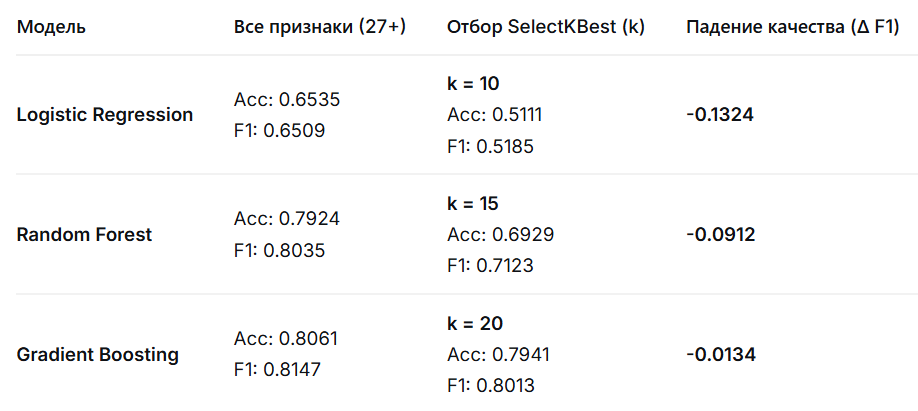
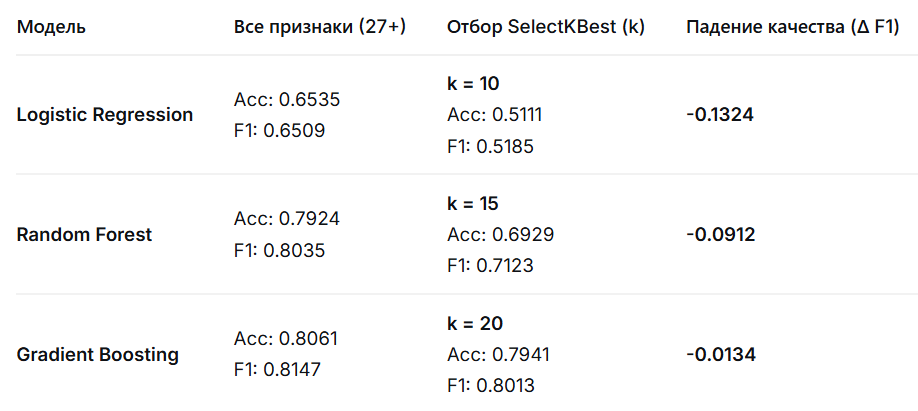

**Вывод:** Использование SelectKBest позволил значительно сократить признаковое пространство (с 27 до 10) только для логистической регрессии. В случае моделей случайного леса и градиентного бустинга невозможно было значительно сократить признаковое пространство без значительного ухудшения качества.

Проверим работу метода рекурсивного исключения - RFE. Его суть заключается в исключения конкретного самого бесполезного признака после обучения модели.

In [17]:
from sklearn.feature_selection import RFE

rfe = RFE(estimator=LogisticRegression(max_iter=1000, class_weight='balanced'), n_features_to_select=21, step=1)
rfe.fit(X_train_scaled, y_train)

X_train_rfe = rfe.transform(X_train_scaled)
X_test_rfe = rfe.transform(X_test_scaled)

print(f"Осталось признаков: {X_train_rfe.shape[1]}")
print(X.columns[rfe.support_])

gb = GradientBoostingClassifier(n_estimators=120, learning_rate=0.20, random_state=42)
gb.fit(X_train_rfe, y_train)
y_pred_gb = gb.predict(X_test_rfe)
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.6f}")
print(f"F1-macro: {f1_score(y_test, y_pred_gb, average='macro'):.6f}")

Осталось признаков: 21
Index(['X_Minimum', 'Y_Minimum', 'X_Perimeter', 'Y_Perimeter',
       'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer',
       'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness',
       'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index',
       'Edges_Y_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index',
       'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas'],
      dtype='object')
Accuracy: 0.801029
F1-macro: 0.823567


**Вывод:** Отбор признаков с помощью RFE - рекурсивное исключение признаков, где в качестве оценщика использовалась Логистическая регрессия, позволил отобрать 21 наиболее информативный признак. Обучение на них Gradient Boosting показало, что удаление шумовых признаков повысило F1-macro с 0.8147 до 0.8235. Это доказывает, что для данной задачи меньшее количество правильных признаков работает лучше, чем большое количество сырых данных.

Попробуем радикально сократить признаковое пространство используя метод главных компонент - PCA. Его основная идея в поиске напрвелния, в котором данные меняются сильнее всего. Минус конечно, что потом сложно будет интерпретировать результат.

In [18]:
from sklearn.decomposition import PCA


pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Было признаков: {X_train_scaled.shape[1]}")
print(f"Осталось компонент после PCA: {X_train_pca.shape[1]}\n")

#посмотрим рса сразу на 3 моделях
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=120, learning_rate=0.2, random_state=42)
}

results = []

for name, model in models.items():
    #обучаем на PCA данных
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    
    #считаем метрики
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    
    results.append({'Модель': name, 'Accuracy': round(acc, 4), 'F1-macro': round(f1, 4)})

#таблица резов
results_df = pd.DataFrame(results).set_index('Модель')
print("Результаты моделей на PCA")
display(results_df)


Было признаков: 27
Осталось компонент после PCA: 12

Результаты моделей на PCA


,Accuracy,F1-macro
Модель,,
Logistic Regression,0.6432,0.6381
Random Forest,0.7376,0.7591
Gradient Boosting,0.7050,0.6961


**Вывод:**
Применение PCA для сжатия признакового пространства с 27 до 12 компонент, сохранив 95.43% исходной информации показало следующее: 
1. Логистическая регрессия сохранила почти исходное качество F1 упал с 0.651 до 0.638. Это объясняется тем, что PCA создает линейные комбинации, которые хорошо ложатся для линейных моделей.
2. Ансамбли деревьев - Random Forest и Gradient Boosting - показали значительное падение качества RF: с 0.803 до 0.759; GB: с 0.815 до 0.696.
Деревья решений ищут четкие пороги в исходных признаках. PCA заменяет исходные признаки абстрактными компонентами, смешивая геометрию и яркость. Деревьям становится сложнее строить правила, поэтому они теряют в качестве.


**ИТОГОВЫЙ ВЫВОД ПО ПЕРВОЙ ГИПОТЕЗЕ**

Гипотеза подтвердилась частично. Сократить пространство без потери качества можно только умным отбором RFE, который оставил 21 признак и повысил F1-macro у Gradient Boosting до 0.8235, тогда как SelectKBest и PCA ухудшили результаты большинства моделей, так как первый теряет нелинейные связи, а второй создает абстрактные компоненты, непонятные деревьям.

# ШАГ 2.2 Проверка второй гипотезы. Статистические тесты.

Конечно же дисбаланс классов в какой-то мере косвенно доказывает, что accurancy менее показательно, чем F1. Однако, я бы хотела провести статистические тесты, чтобы полностью подтвердить гипотезу.

1 Тест. Dummy Classifier  - обучаем модель на то, чтобы она определяла только самый распространненный класс (другие дефекты). И смотрим как отличаются accurancy и f1-macro. Интуитивно понятно, что accurancy будет выше, но хотелось бы посмотреть порядок, насколько отличаются метрики.

2 Тест. Z-тест - его суть в сравнении насколько предсказания Dummy-модели отличаются от наших и насколько они статистически различимы. Если значение больше 1.96 (для 95% доверительного интервала), то разница не случайна.

3 Тест. Посмотрим разброс F1 для разных классов, чтобы показать, что эта метрика хорошо или плохо отображает модель.

In [19]:
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print(f"Dummy Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"Dummy F1-macro: {f1_score(y_test, y_pred_dummy, average='macro'):.4f}\n")

#Z-тест
n = len(y_test)
p1 = accuracy_score(y_test, y_pred_dummy)
p2 = accuracy_score(y_test, y_pred) 

p_pool = (p1 + p2) / 2
se = np.sqrt(p_pool * (1 - p_pool) * (2 / n))
z_stat = (p2 - p1) / se
print(f"Z-статистика для Accuracy: {z_stat:.4f}")
print(f"Разница в Accuracy: {abs(p2 - p1):.4f}\n")

#анализ разброса F1 по классам
report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
f1_scores = [report[cls]['f1-score'] for cls in le.classes_]
supports = [report[cls]['support'] for cls in le.classes_]

print("F1-score по классам:")
for cls, f1, sup in zip(le.classes_, f1_scores, supports):
    print(f"{cls:15} | F1: {f1:.4f} | Объектов в тесте: {int(sup)}")

print(f"\nСреднеквадратичное отклонение F1 по классам: {np.std(f1_scores):.4f}")
print(f"Разница между лучшим и худшим F1: {max(f1_scores) - min(f1_scores):.4f}")

Dummy Accuracy: 0.3465
Dummy F1-macro: 0.0735

Z-статистика для Accuracy: 12.2575
Разница в Accuracy: 0.3585

F1-score по классам:
Bumps           | F1: 0.5702 | Объектов в тесте: 121
Dirtiness       | F1: 0.7059 | Объектов в тесте: 17
K_Scatch        | F1: 0.9204 | Объектов в тесте: 117
Other_Faults    | F1: 0.6769 | Объектов в тесте: 202
Pastry          | F1: 0.4557 | Объектов в тесте: 47
Stains          | F1: 0.7027 | Объектов в тесте: 22
Z_Scratch       | F1: 0.8411 | Объектов в тесте: 57

Среднеквадратичное отклонение F1 по классам: 0.1442
Разница между лучшим и худшим F1: 0.4647


1. Если всегда относить к другим дефектам, то accurancy 0.35, а F1-macro 0.0735 (практически 0). Это говорит, что ориентирование только на accurancy может привести к набору accurancy за просто угадывание.
2. Z-тест показал, что accurancy статистически различимы для двух моделей (глупой и обученной)
3. Очень сильно различие F1 по классам, причем раница значительная. Посмотрим дальше на матрице ошибок какие классы чаще всего путаются.

Матрица ошибок в нормализированном виде, чтобы понимали именно долю.

In [20]:
cm_normalized = confusion_matrix(y_test, y_pred, normalize='true')
plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Предсказано (доли)')
plt.ylabel('Реально')
plt.title('Нормализованная матрица ошибок')
plt.show()

NameError: name 'confusion_matrix' is not defined

Все у целом неплохо распределяется за исключением других дефектов - в них мешают все остальные классы. Модель систематически путает Bumps и Pastry. Меня наводит это на мысль, что необходимо в метрики добавить обязательно ROC-AUC, чтобы помимо бинарной оценки - угадала модель класс или нет, мы еще видели какая вероятность.

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_macro = roc_auc_score(y_test, rf.predict_proba(X_test), multi_class='ovr', average='macro')
print(f"ROC-AUC (macro): {roc_auc_macro:.4f}")

**ИТОГОВЫЙ ВЫВОД ПО ГИПОТЕЗЕ 2**

Гипотеза Н2 подтвердилась. Accuracy оказалась неинформативной - Dummy-модель дала 0.3465 при F1-macro всего 0.0735, показав, что точность можно набрать без реального распознавания редких классов. Наша модель с Accuracy 0.70 и F1-macro 0.75 имеет сильный разброс качества от 0.46 до 0.92. Дополнительно увидели, что низкий ROC-AUC 0.6454 и матрица ошибок показали главную проблему: модель плохо разделяет классы на уровне вероятностей. 


# ШАГ 2.3 Проверка третьей гипотезы. Вывод 

Сравнение моделей показало, что ансамбли деревьев значительно превзошли линейную модель. 
Логистическая регрессия достигла F1-macro 0.6509, в то время как Random Forest показал 0.8035, а Gradient Boosting - 0.8147. Разница составила более 15%, что опровергает предположение о линейной природе данных. 

Причина в том, что дефекты стальных листов имеют сложную нелинейную структуру. Для их распознавания недостаточно просто знать размеры или яркость, важно их пространственное взаимодействие и форма. Логистическая регрессия не может уловить такие зависимости, так как она строит только линейные границы. Таким образом, данные имеют нелинейную природу, и для этой задачи ансамбли деревьев являются более подходящим выбором.

**ИТОГОВЫЙ ВЫВОД ПО ГИПОТЕЗЕ 3**

Гипотеза Н3 не подтвердилась. Ансамбли деревьев значительно превзошли линейную модель

# ШАГ 2.4 Проверка четвертой гипотезы. Поиск самых важных признаков. 

Проверку данной гипотезы хотелось бы провести на модели градиентного бустинга, потому что она показала лучшее качество и стабильность. 

Обучаем на всех признаках, а потом достаем важность признаков и для наглядности строим график.

In [ ]:
rf_imp = GradientBoostingClassifier(n_estimators=100, random_state=42)
rf_imp.fit(X_train, y_train)

importances = pd.Series(rf_imp.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='viridis')
plt.title('Топ-15 самых важных признаков')
plt.xlabel('Важность')
plt.show()

**ИТОГОВЫЙ ВАРИАНТ ПО ГИПОТЕЗЕ 4**

Подтвердилась частично. Анализ важности признаков показал, что геометрия дефекта действительно играет ключевую роль, но не абсолютную. На первом месте по важности оказался логарифмический индекс по оси , а в топ-10 также вошли площадь, логарифм площади, координаты и индекс квадратности. Однако гипотеза о доминировании геометрии нарушена наличием негеометрических признаков в топе. На втором и третьем местах расположились толщина листа  и длина конвейера , которые являются характеристиками самого проката, а не дефекта. Кроме того, признаки освещенности также вошли в топ-15, обогнав некоторые геометрические параметры.

# ШАГ 2.5 Проверка пятой гипотезы. Статистические тест Т-Стьюдента.

Нам необходимо проверить отличаются ли признаки для двух марок сталей. Проверим средние значения для царапин, потому что другие виды дефектов имеют сильную вариативность, которая отвечает скорее на вопрос как, чем и природа дефекта, а не про сами свойства металла. Царапины же и их вид как раз косвено отражает механические свойства материала и его предрасположенность к дефекту. Также будем рассматривать именно геометрические признаки дефекта.

In [ ]:
from scipy.stats import ttest_ind

geo_features = ['Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index']
target_col = ["Z_Scratch", "K_Scatch"]

results = []

for fault in target_col:
    df_fault = df[df[fault] == 1]
    
    for feature in geo_features:
        group_a300 = df_fault[df_fault['TypeOfSteel_A300'] == 1][feature]
        group_a400 = df_fault[df_fault['TypeOfSteel_A300'] == 0][feature]
        
        if len(group_a300) < 2 or len(group_a400) < 2:
            continue
            
        stat, p_val = ttest_ind(group_a300, group_a400, equal_var=False)
        
        results.append({
            'Класс': fault,
            'Геом. признак': feature,
            'Ср. A300': round(group_a300.mean(), 2),
            'Ср. A400': round(group_a400.mean(), 2),
            'p-value': round(p_val, 5), # Оставляем 5 знаков, чтобы видеть мелкие различия
            'Различия?': 'ДА' if p_val < 0.05 else 'НЕТ'
        })

results_df = pd.DataFrame(results)
display(results_df)

# Считаем статистику
total_tests = len(results_df)
sig_tests = len(results_df[results_df['Различия?'] == 'ДА'])
print(f"\nВсего тестов по геометрии: {total_tests}. Из них значимых различий: {sig_tests}.")

**ИТОГОВЫЙ ВЫВОД ПО ГИПОТЕЗЕ 5.**

Гипотеза подтвердилась. Марка стали не влияет на форму и размер дефекта, а определяет только прочностные свойства металла, которые для данных марок не ощутимо различаемы.

# ШАГ 3. Доработка модели RANDOM FOREST. Подбор гиперпараметров. Кросс-валидация.

Есть два самых популярных варианта поиска гиперпараметров - GridSearch и RandomizedSearch. Суть первого заключается в том, что делит данные на блоки и на каждом из блоков выбирает параметры. Случайный поиск же случайным образов выбирает, что проверять и делает сколько раз мы указываем. Хочу проверить теорию: найденные гиперпараметры могут дать примерно одинаковое качество, тогда как время для их поиска существенно будет различаться.

In [ ]:
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import f1_score


param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

#GRID SEARCH
print("GridSearchCV")
start_grid = time.time()

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
time_grid = time.time() - start_grid

y_pred_grid = grid_search.best_estimator_.predict(X_test)
f1_grid = f1_score(y_test, y_pred_grid, average='macro')

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"F1-macro на тесте: {f1_grid:.4f}")
print(f"Время выполнения: {time_grid:.2f} сек.\n")


#RANDOMIZED SEARCH 

print("RandomizedSearchCV")
start_random = time.time()

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)
time_random = time.time() - start_random

y_pred_random = random_search.best_estimator_.predict(X_test)
f1_random = f1_score(y_test, y_pred_random, average='macro')

print(f"Лучшие параметры: {random_search.best_params_}")
print(f"F1-macro на тесте: {f1_random:.4f}")
print(f"Время выполнения: {time_random:.2f} сек.\n")


#итоговая таблица
comparison = pd.DataFrame({
    'Метод': ['GridSearch', 'RandomizedSearch'],
    'F1-macro на тесте': [round(f1_grid, 4), round(f1_random, 4)],
    'Время (сек)': [round(time_grid, 2), round(time_random, 2)]
})

print("Итоговое сравнение")
display(comparison)

**Вывод:**
Моя теория подтвердилась. Время отличается примерно в 6 раз, тогда как качество на тесте одинаковое. 